Check the video properties


OpenCV 5.0.0
size 1080x1920 | fps 30.00 | frames 694 | duration 23.1 s | codec h264
frame 0: read OK
frame 347: read OK
frame 689: read OK


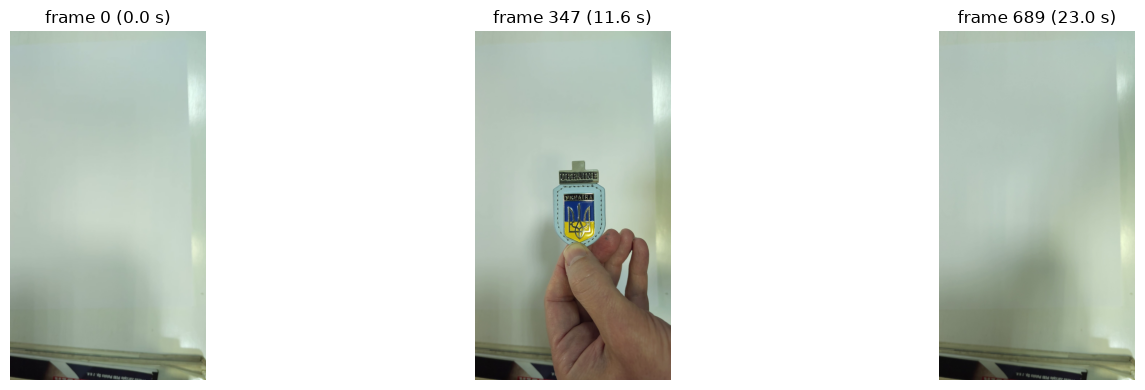

writer opened: True
writer test file: 205 KB (should be > 0)


In [1]:
import cv2, numpy as np, matplotlib.pyplot as plt, json, csv, time
from pathlib import Path
print("OpenCV", cv2.__version__)

VIDEO = Path("data") / "task09_track.mp4"
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

cap = cv2.VideoCapture(str(VIDEO))
assert cap.isOpened(), f"Cannot open {VIDEO}"

fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
code = int(cap.get(cv2.CAP_PROP_FOURCC)); codec = "".join(chr((code >> 8 * i) & 0xFF) for i in range(4))
print(f"size {W}x{H} | fps {fps:.2f} | frames {n_frames} | duration {n_frames / fps:.1f} s | codec {codec}")

# read 3 frames (start, middle, end) to confirm decoding works
idx = [0, n_frames // 2, max(n_frames - 5, 0)]
frames = []
for i in idx:
    cap.set(cv2.CAP_PROP_POS_FRAMES, i)
    ok, f = cap.read()
    print(f"frame {i}: read {'OK' if ok else 'FAILED'}")
    if ok: frames.append((i, f))
cap.release()

fig, ax = plt.subplots(1, len(frames), figsize=(16, 4))
for a, (i, f) in zip(np.atleast_1d(ax), frames):
    a.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)); a.set_title(f"frame {i} ({i / fps:.1f} s)"); a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS / "task09_step1_frames.png", dpi=100); plt.show()

# writer test: 30 resized frames -> small mp4
OUT_W = 960; OUT_H = round(H * OUT_W / W)
writer = cv2.VideoWriter(str(RESULTS / "task09_writer_test.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), fps, (OUT_W, OUT_H))
print("writer opened:", writer.isOpened())
cap = cv2.VideoCapture(str(VIDEO))
for _ in range(30):
    ok, f = cap.read()
    if not ok: break
    writer.write(cv2.resize(f, (OUT_W, OUT_H), interpolation=cv2.INTER_AREA))
writer.release(); cap.release()
size = (RESULTS / "task09_writer_test.mp4").stat().st_size
print(f"writer test file: {size / 1024:.0f} KB (should be > 0)")

Step 5: Comparison in the notebook

{'tracker': 'CSRT', 'fps': np.float64(13.2), 'mean_ms': np.float64(75.9), 'ok_while_visible_pct': np.float64(100.0), 'lost_while_visible': 0, 'false_ok_after_exit': '29/35', 'box_w': '142-199', 'box_h': '233-326'}
{'tracker': 'KCF', 'fps': np.float64(49.9), 'mean_ms': np.float64(20.1), 'ok_while_visible_pct': np.float64(100.0), 'lost_while_visible': 0, 'false_ok_after_exit': '0/35', 'box_w': '33-148', 'box_h': '242-242', 'dist_to_csrt_mean': np.float64(13.6), 'dist_to_csrt_max': np.float64(34.0)}
{'tracker': 'MIL', 'fps': np.float64(10.6), 'mean_ms': np.float64(94.6), 'ok_while_visible_pct': np.float64(100.0), 'lost_while_visible': 0, 'false_ok_after_exit': '35/35', 'box_w': '148-148', 'box_h': '242-242', 'dist_to_csrt_mean': np.float64(8.4), 'dist_to_csrt_max': np.float64(74.1)}


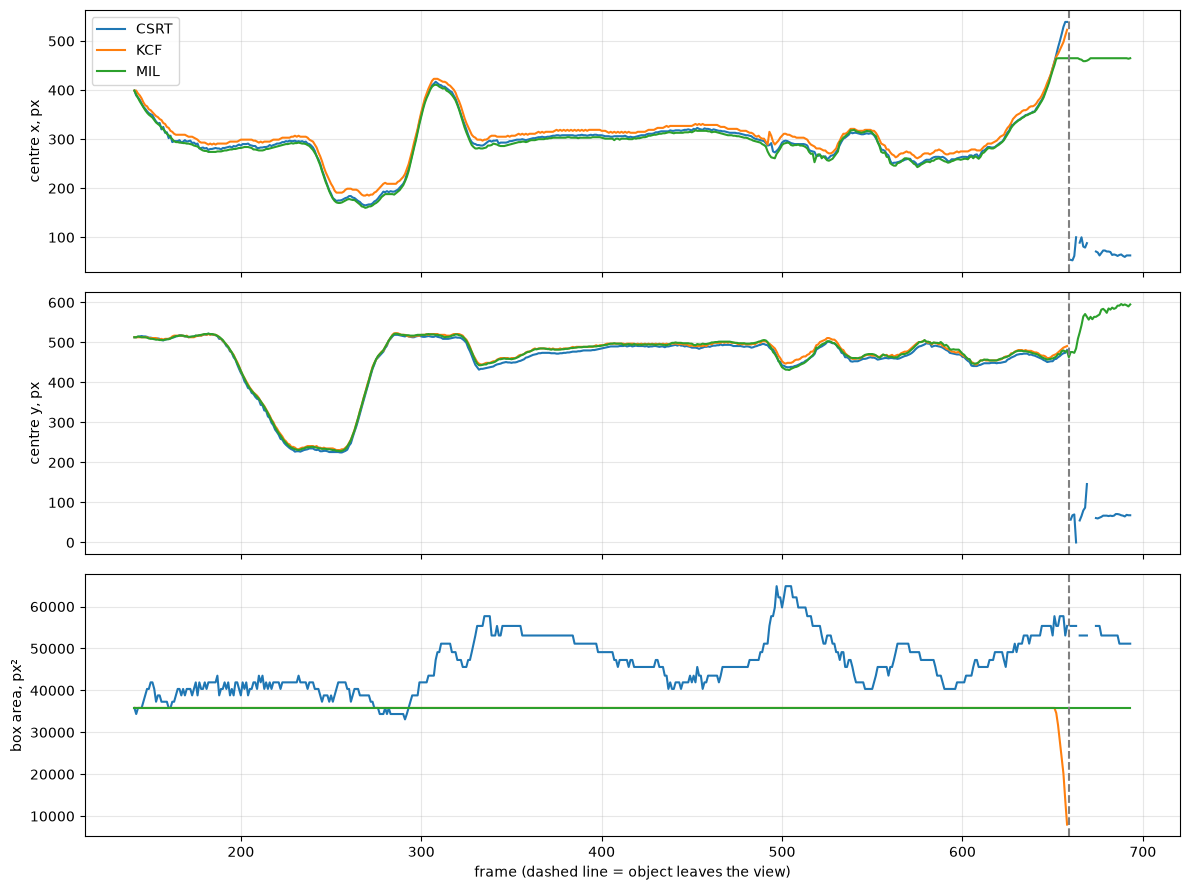

In [2]:
NAMES = ["csrt", "kcf", "mil"]
EXIT_FRAME = 659          # first frame where the object has left the view (check in the video; adjust if needed)
START = json.loads((RESULTS / "task09_roi.json").read_text())["start_frame"]

def load_log(name):
    with open(RESULTS / f"task09_{name}.csv") as f:
        rows = list(csv.DictReader(f))
    return {k: np.array([float(r[k]) for r in rows]) for k in rows[0]}

logs = {n: load_log(n) for n in NAMES}
ref = logs["csrt"]                                    # reference for drift comparison

table = []
for n, L in logs.items():
    fr, ok, ms = L["frame"][1:], L["ok"][1:], L["update_ms"][1:]
    w, h, cx, cy = L["w"][1:], L["h"][1:], L["cx"][1:], L["cy"][1:]
    vis, gone = fr < EXIT_FRAME, fr >= EXIT_FRAME
    row = dict(tracker=n.upper(), fps=round(1000 / ms.mean(), 1), mean_ms=round(ms.mean(), 1),
               ok_while_visible_pct=round(100 * ok[vis].mean(), 1),
               lost_while_visible=int((ok[vis] == 0).sum()),
               false_ok_after_exit=f"{int(ok[gone].sum())}/{int(gone.sum())}",
               box_w=f"{int(w[ok == 1].min())}-{int(w[ok == 1].max())}",
               box_h=f"{int(h[ok == 1].min())}-{int(h[ok == 1].max())}")
    if n != "csrt":                                   # centre distance to CSRT while both report success
        both = vis & (ok == 1) & (ref["ok"][1:] == 1)
        d = np.hypot(cx[both] - ref["cx"][1:][both], cy[both] - ref["cy"][1:][both])
        row.update(dist_to_csrt_mean=round(d.mean(), 1), dist_to_csrt_max=round(d.max(), 1))
    table.append(row)

for r in table: print(r)
with open(RESULTS / "task09_comparison.csv", "w", newline="") as f:
    keys = sorted({k for r in table for k in r}, key=lambda k: list(table[1]).index(k) if k in table[1] else 99)
    wr = csv.DictWriter(f, fieldnames=keys); wr.writeheader(); wr.writerows(table)

# trajectories: centre x, centre y and box area per frame (gaps = tracker reported LOST)
fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for n, L in logs.items():
    m = np.where(L["ok"] == 1, 1.0, np.nan)
    ax[0].plot(L["frame"], L["cx"] * m, label=n.upper())
    ax[1].plot(L["frame"], L["cy"] * m, label=n.upper())
    ax[2].plot(L["frame"], L["w"] * L["h"] * m, label=n.upper())
for a, lab in zip(ax, ["centre x, px", "centre y, px", "box area, px²"]):
    a.axvline(EXIT_FRAME, color="gray", ls="--"); a.set_ylabel(lab); a.grid(alpha=0.3)
ax[0].legend(); ax[2].set_xlabel("frame (dashed line = object leaves the view)")
plt.tight_layout(); plt.savefig(RESULTS / "task09_trajectories.png", dpi=110); plt.show()